# Unit 3 – Ex 4: Polynomial regression
18 cars passing a certain tollbooth at different times of the day (x) with different speed (y).

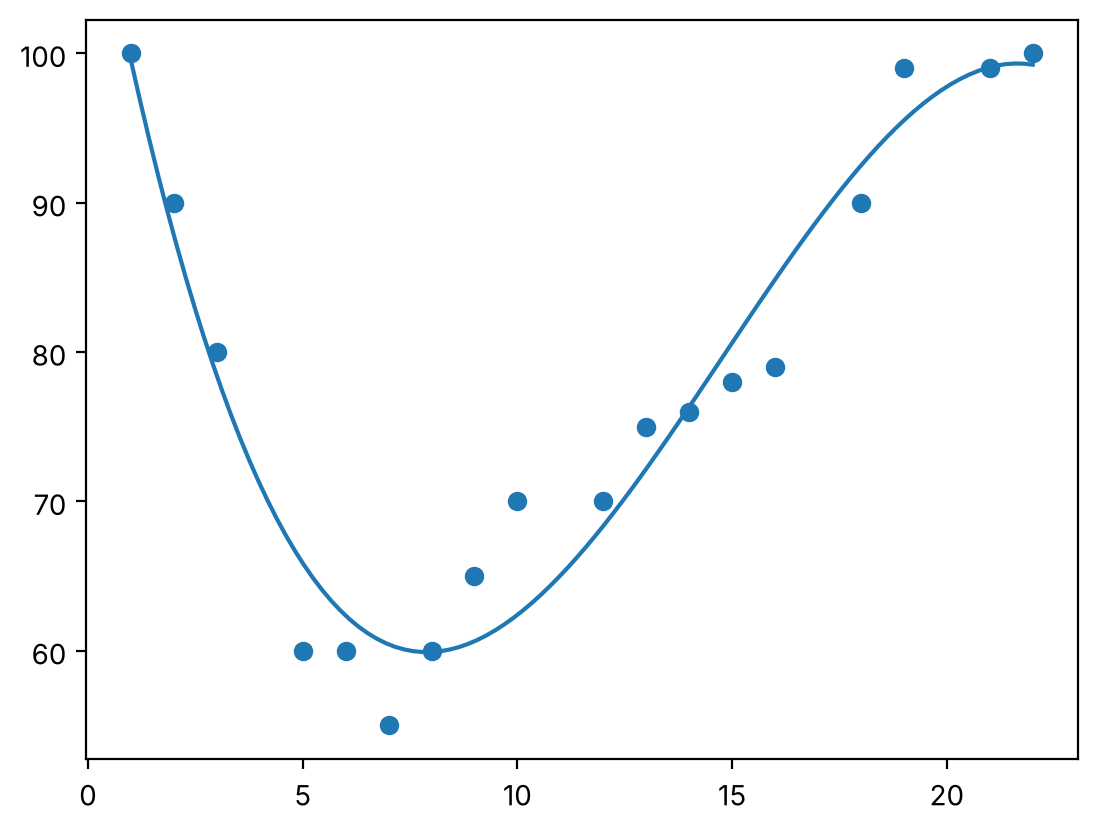

In [1]:
import numpy
import matplotlib.pyplot as plt

x = [1,2,3,5,6,7,8,9,10,12,13,14,15,16,18,19,21,22]
y = [100,90,80,60,60,55,60,65,70,70,75,76,78,79,90,99,99,100]

mymodel = numpy.poly1d(numpy.polyfit(x, y, 3))
myline = numpy.linspace(1, 22, 100)

plt.scatter(x, y)
plt.plot(myline, mymodel(myline))
plt.show()

In [2]:
from sklearn.metrics import r2_score
print(r2_score(y, mymodel(x)))

0.9432150416451026


## Predict Future Values (original) – speed at about 17:00

In [3]:
speed = mymodel(17)
print(speed)

88.87331269697984


## Experiment 1 – Change the polynomial degree
The `3` in `polyfit(x, y, 3)` is the degree. R² on the training data always goes up as the degree goes up. Leave-one-out error (fit on 17 points, predict the one left out) shows whether the model actually predicts new points better.

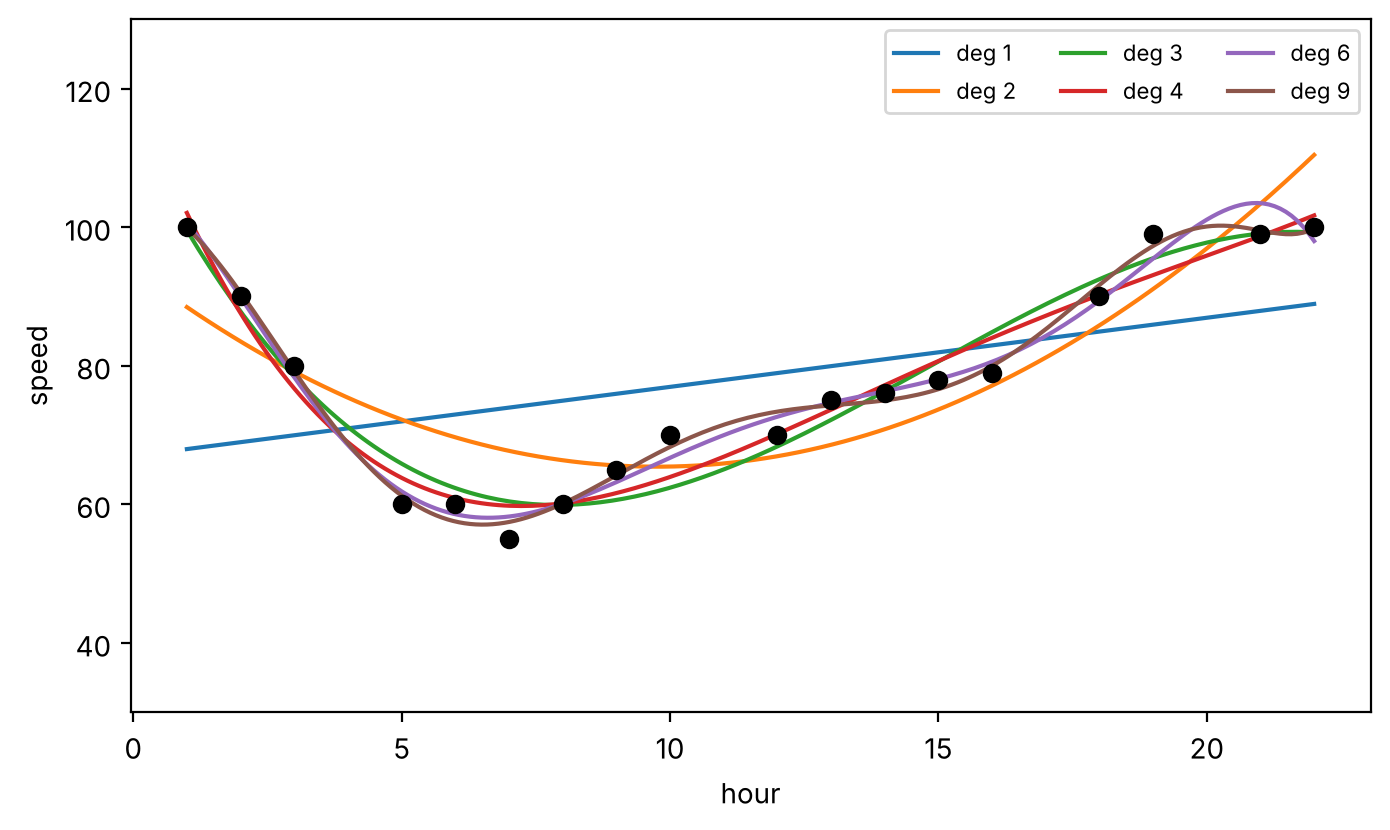

,degree,R² (train),LOO RMSE,pred @17,pred @24 (extrapolate)
0,1,0.182,15.758,83.930,90.912
1,2,0.760,9.437,81.176,126.319
2,3,0.943,4.235,88.873,95.452
3,4,0.954,4.592,87.211,108.928
4,6,0.980,6.378,84.289,32.867
5,9,0.990,20.550,85.274,180.665


In [4]:
import numpy as np, pandas as pd
xa, ya = np.array(x), np.array(y)
rows = []
fig, ax = plt.subplots(figsize=(8, 4.5)); ax.scatter(xa, ya, c='k', zorder=3)
grid = np.linspace(1, 22, 200)
for d in [1, 2, 3, 4, 6, 9]:
    m = np.poly1d(np.polyfit(xa, ya, d))
    loo = [(ya[i] - np.poly1d(np.polyfit(np.delete(xa,i), np.delete(ya,i), d))(xa[i]))**2 for i in range(len(xa))]
    rows.append({'degree': d, 'R² (train)': r2_score(ya, m(xa)), 'LOO RMSE': np.sqrt(np.mean(loo)),
                 'pred @17': m(17), 'pred @24 (extrapolate)': m(24)})
    ax.plot(grid, m(grid), label=f'deg {d}')
ax.set_ylim(30, 130); ax.legend(ncol=3, fontsize=8); ax.set_xlabel('hour'); ax.set_ylabel('speed'); plt.show()
pd.DataFrame(rows).round(3)

## Experiment 2 – Change the data points
Remove the early-morning points, add noise, or add one odd reading, then refit the degree-3 model.

In [5]:
def deg3(xx, yy):
    m = np.poly1d(np.polyfit(xx, yy, 3)); return {'n': len(xx), 'R²': r2_score(yy, m(xx)), 'pred @17': m(17)}
np.random.seed(0)
scen = {
    'original': (xa, ya),
    'drop hours 1-3': (xa[xa > 3], ya[xa > 3]),
    'add noise (sd=8)': (xa, ya + np.random.normal(0, 8, len(ya))),
    'add odd reading (17, 40)': (np.append(xa, 17), np.append(ya, 40)),
}
pd.DataFrame({k: deg3(*v) for k, v in scen.items()}).T.round(3)

,n,R²,pred @17
original,18.0,0.943,88.873
drop hours 1-3,15.0,0.964,86.813
add noise (sd=8),18.0,0.858,93.054
"add odd reading (17, 40)",19.0,0.580,81.155


### What changed
* Degree 1 (a straight line) explains almost none of the U-shape (R² 0.18). Degree 2 gets to 0.76 and degree 3 to 0.94.
* Raising the degree keeps pushing training R² up. Leave-one-out error is lowest at degree 3 and gets worse at high degrees: the curve is fitting noise, i.e. **overfitting**.
* Within the data range the predictions at 17:00 are similar, but **outside it (x=24) high-degree models give very different answers**. Polynomials blow up when extrapolated.
* Adding noise drops R² to about 0.86. A single odd reading at 17:00 drops R² to 0.58 and pulls the 17:00 prediction from 88.9 down to 81.2.